# Soal 7 — Optimasi Multi-output Energy Efficiency dengan PSO

**Nama:** Marsa Naufal 
**NIM:** 04231047  
**Seed:** 47 
**Dataset:** D3 — Energy Efficiency, UCI (768 bangunan hasil simulasi, 8 fitur, target Heating Load $Y_1$ dan Cooling Load $Y_2$)
**Library:** `pyswarms` (Particle Swarm Optimization), `pandas`/`numpy`/`scikit-learn`.

## 1. Business Understanding

**Latar belakang.** Sebelum gedung dibangun, arsitek ingin tahu kira-kira berapa energi pemanas ($Y_1$) dan pendingin ($Y_2$) yang dibutuhkan, karena keduanya menentukan ukuran AC/heater dan biaya operasional seumur gedung. Simulasi energi detail itu lambat, jadi dibutuhkan model cepat yang bisa memperkirakan $Y_1$ dan $Y_2$ langsung dari bentuk gedung. Ibaratnya "kalkulator kasar" sebelum masuk ke perhitungan detail.

**Rumusan masalah.**
1. Bisakah PSO menemukan koefisien dua model linear ($Y_1$ dan $Y_2$) sekaligus dalam satu partikel dengan objective gabungan $J$?
2. Bagaimana pengaruh cara menangani batas (*clipping* vs *reflection*) terhadap hasil PSO?
3. Fitur bangunan mana yang paling dominan, dan seberapa bisa dipercaya interpretasi koefisiennya?

**Tujuan.** Membangun dua model linear terstandardisasi yang dioptimasi PSO, mengevaluasinya di test set, dan menafsirkan koefisiennya secara kritis.

**Kriteria kesuksesan.**

| Kriteria | Ambang |
|---|---|
| PSO mendekati solusi analitik OLS (*least squares*) di data latih | $J_{PSO}$ ≤ 1.01 × $J_{OLS}$ |
| Akurasi test set untuk masing-masing target | $R^2$ ≥ 0.85 |
| Kesalahan relatif | RMSE ≤ 0.4 σ target (setara $R^2$ ≈ 0.84) |

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import time
from pyswarms.single.global_best import GlobalBestPSO
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error
import logging
logging.getLogger("pyswarms").setLevel(logging.WARNING)   # matikan log per-iterasi

SEED = 47
np.random.seed(SEED)
pd.set_option("display.width", 160)
plt.rcParams["figure.dpi"] = 110

## 2. Data Understanding

### 2.1 Memuat data dan sampel

In [2]:
nama = {"X1": "Relative_Compactness", "X2": "Surface_Area", "X3": "Wall_Area", "X4": "Roof_Area",
        "X5": "Overall_Height", "X6": "Orientation", "X7": "Glazing_Area", "X8": "Glazing_Area_Distribution",
        "Y1": "Heating_Load", "Y2": "Cooling_Load"}
df = pd.read_excel("data/energy+efficiency/ENB2012_data.xlsx").rename(columns=nama)
FEAT = list(nama.values())[:8]
TARGET = ["Heating_Load", "Cooling_Load"]
print("Ukuran data:", df.shape)
df.head(20)

Ukuran data: (768, 10)


,Relative_Compactness,Surface_Area,Wall_Area,Roof_Area,Overall_Height,Orientation,Glazing_Area,Glazing_Area_Distribution,Heating_Load,Cooling_Load
0,0.98,514.5,294.0,110.25,7.0,2,0.0,0,15.55,21.33
1,0.98,514.5,294.0,110.25,7.0,3,0.0,0,15.55,21.33
2,0.98,514.5,294.0,110.25,7.0,4,0.0,0,15.55,21.33
3,0.98,514.5,294.0,110.25,7.0,5,0.0,0,15.55,21.33
4,0.90,563.5,318.5,122.50,7.0,2,0.0,0,20.84,28.28
5,0.90,563.5,318.5,122.50,7.0,3,0.0,0,21.46,25.38
6,0.90,563.5,318.5,122.50,7.0,4,0.0,0,20.71,25.16
7,0.90,563.5,318.5,122.50,7.0,5,0.0,0,19.68,29.60
8,0.86,588.0,294.0,147.00,7.0,2,0.0,0,19.50,27.30
9,0.86,588.0,294.0,147.00,7.0,3,0.0,0,19.95,21.97


### 2.2 Atribut dan tipe data

| Kolom | Arti | Tipe / nilai unik |
|---|---|---|
| Relative_Compactness (X1) | kekompakan bentuk gedung (makin besar = makin "kotak padat") | numerik, 12 nilai |
| Surface_Area (X2) | luas seluruh permukaan luar, m² | numerik, 12 nilai |
| Wall_Area (X3) | luas dinding, m² | numerik, 7 nilai |
| Roof_Area (X4) | luas atap, m² | numerik, 4 nilai |
| Overall_Height (X5) | tinggi gedung, m | numerik, hanya 3.5 atau 7 |
| Orientation (X6) | arah hadap: 2=utara, 3=timur, 4=selatan, 5=barat | kategorikal berkode angka |
| Glazing_Area (X7) | persentase luas kaca: 0, 10, 25, 40% | numerik diskret |
| Glazing_Area_Distribution (X8) | sebaran kaca: 0=tanpa kaca, 1–5 = seragam/utara/timur/selatan/barat | kategorikal berkode angka |
| Heating_Load (Y1) | beban pemanas, kWh/m² | numerik kontinu (target) |
| Cooling_Load (Y2) | beban pendingin, kWh/m² | numerik kontinu (target) |

Dataset ini **hasil simulasi** (12 bentuk gedung × variasi kaca dan orientasi), bukan pengukuran lapangan, sehingga tiap fitur hanya punya sedikit nilai unik.

In [3]:
df.info()
print("\nJumlah nilai unik:\n", df.nunique().to_string())

<class 'pandas.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 10 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   Relative_Compactness       768 non-null    float64
 1   Surface_Area               768 non-null    float64
 2   Wall_Area                  768 non-null    float64
 3   Roof_Area                  768 non-null    float64
 4   Overall_Height             768 non-null    float64
 5   Orientation                768 non-null    int64  
 6   Glazing_Area               768 non-null    float64
 7   Glazing_Area_Distribution  768 non-null    int64  
 8   Heating_Load               768 non-null    float64
 9   Cooling_Load               768 non-null    float64
dtypes: float64(8), int64(2)
memory usage: 60.1 KB

Jumlah nilai unik:
 Relative_Compactness          12
Surface_Area                  12
Wall_Area                      7
Roof_Area                      4
Overall_Height                

### 2.3 Statistik deskriptif, missing value, duplikasi, outlier

In [4]:
display(df.describe().T.round(3))
print("Missing value total :", df.isna().sum().sum())
print("Baris duplikat      :", df.duplicated().sum())
q1, q3 = df.quantile(.25), df.quantile(.75); iqr = q3 - q1
print("Outlier 1.5×IQR per kolom:\n", ((df < q1 - 1.5 * iqr) | (df > q3 + 1.5 * iqr)).sum().to_string())

,count,mean,std,min,25%,50%,75%,max
Relative_Compactness,768.0,0.764,0.106,0.62,0.682,0.75,0.830,0.98
Surface_Area,768.0,671.708,88.086,514.50,606.375,673.75,741.125,808.50
Wall_Area,768.0,318.500,43.626,245.00,294.000,318.50,343.000,416.50
Roof_Area,768.0,176.604,45.166,110.25,140.875,183.75,220.500,220.50
Overall_Height,768.0,5.250,1.751,3.50,3.500,5.25,7.000,7.00
Orientation,768.0,3.500,1.119,2.00,2.750,3.50,4.250,5.00
Glazing_Area,768.0,0.234,0.133,0.00,0.100,0.25,0.400,0.40
Glazing_Area_Distribution,768.0,2.812,1.551,0.00,1.750,3.00,4.000,5.00
Heating_Load,768.0,22.307,10.090,6.01,12.992,18.95,31.668,43.10
Cooling_Load,768.0,24.588,9.513,10.90,15.620,22.08,33.132,48.03


Missing value total : 0
Baris duplikat      : 0
Outlier 1.5×IQR per kolom:
 Relative_Compactness         0
Surface_Area                 0
Wall_Area                    0
Roof_Area                    0
Overall_Height               0
Orientation                  0
Glazing_Area                 0
Glazing_Area_Distribution    0
Heating_Load                 0
Cooling_Load                 0


### 2.4 Visualisasi

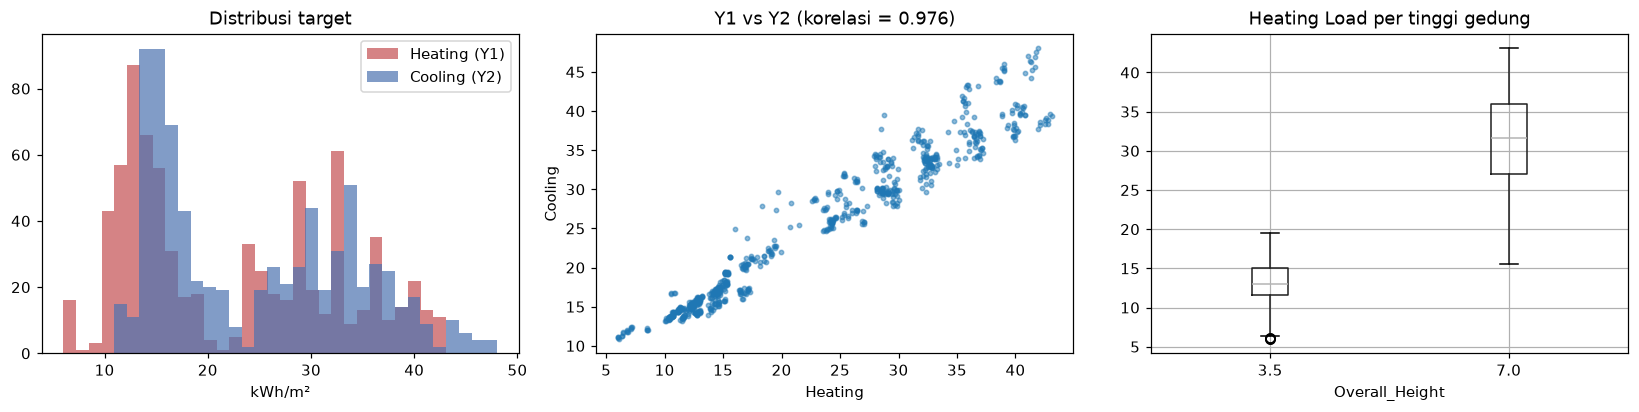

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
axes[0].hist(df["Heating_Load"], bins=30, color="#C44E52", alpha=.7, label="Heating (Y1)")
axes[0].hist(df["Cooling_Load"], bins=30, color="#4C72B0", alpha=.7, label="Cooling (Y2)")
axes[0].set_title("Distribusi target"); axes[0].set_xlabel("kWh/m²"); axes[0].legend()
axes[1].scatter(df["Heating_Load"], df["Cooling_Load"], s=8, alpha=.5)
axes[1].set_title(f"Y1 vs Y2 (korelasi = {df[TARGET].corr().iloc[0,1]:.3f})"); axes[1].set_xlabel("Heating"); axes[1].set_ylabel("Cooling")
df.boxplot(column="Heating_Load", by="Overall_Height", ax=axes[2]); axes[2].set_title("Heating Load per tinggi gedung"); plt.suptitle("")
plt.tight_layout(); plt.show()

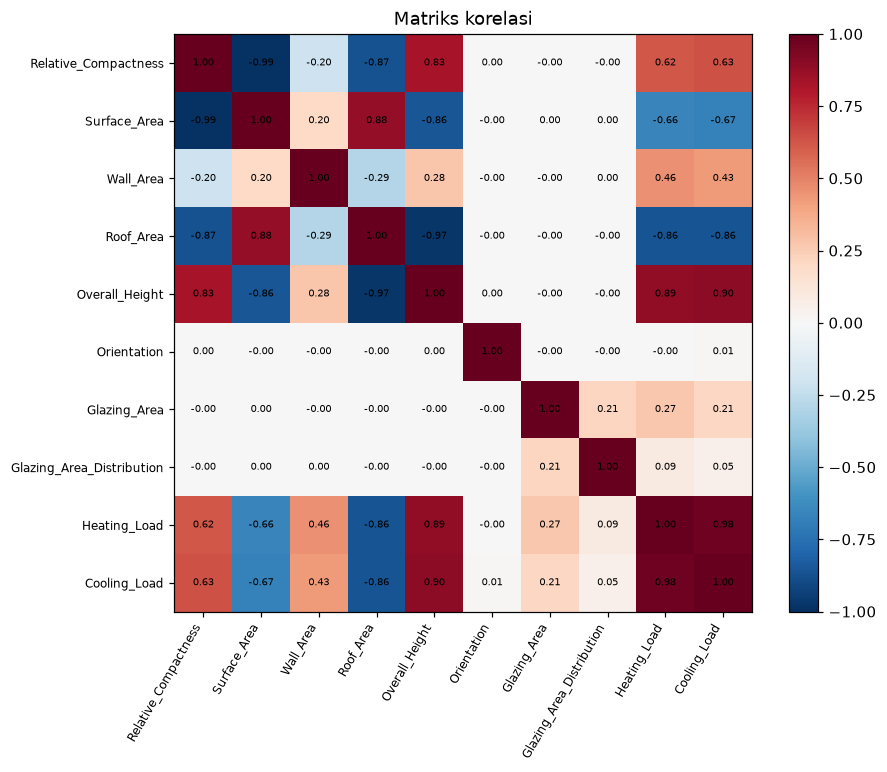

In [6]:
corr = df.corr()
plt.figure(figsize=(8.5, 7))
plt.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1); plt.colorbar()
plt.xticks(range(10), corr.columns, rotation=60, ha="right", fontsize=8); plt.yticks(range(10), corr.columns, fontsize=8)
for i in range(10):
    for j in range(10):
        plt.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=6.5)
plt.title("Matriks korelasi"); plt.tight_layout(); plt.show()

In [7]:
# Cek hubungan linear sempurna: luas permukaan = dinding + 2 × atap ?
selisih = (df["Surface_Area"] - (df["Wall_Area"] + 2 * df["Roof_Area"])).abs().max()
print("max |Surface - (Wall + 2·Roof)| =", selisih)
print("Rank matriks 8 fitur =", np.linalg.matrix_rank(df[FEAT].values))

max |Surface - (Wall + 2·Roof)| = 0.0
Rank matriks 8 fitur = 7


**Interpretasi Data Understanding.**
- Ada **768 baris dan 10 kolom**, tanpa missing value, duplikat, maupun outlier (semua kolom 0 outlier menurut aturan IQR). Ini wajar karena datanya hasil simulasi yang rapi.
- **Heating dan Cooling Load sangat berkorelasi (0.976)**. Gedung yang boros pemanas juga boros pendingin, jadi kedua model kemungkinan punya pola koefisien yang mirip.
- Distribusi target **bimodal** (dua puncak). Boxplot menunjukkan penyebabnya: **Overall_Height** hanya bernilai 3.5 m atau 7 m, dan gedung 7 m bebannya jauh lebih tinggi. Fitur ini kandidat kuat fitur dominan.
- **Masalah serius: multikolinearitas.**
  - Relative_Compactness vs Surface_Area berkorelasi **−0.99**, dan Roof_Area vs Overall_Height **−0.97**.
  - Lebih parah lagi, **Surface_Area = Wall_Area + 2 × Roof_Area secara persis** (selisih maksimum 0), sehingga rank matriks fitur hanya **7, bukan 8**.
  - Artinya satu fitur sebenarnya "kembaran gabungan" fitur lain. Ini berdampak besar pada interpretasi koefisien di Jawaban 7d.
- Orientation dan Glazing_Area_Distribution hampir tidak berkorelasi dengan target (|r| < 0.1).

## 3. Data Preparation

1. **Pembersihan.** Tidak ada missing value, duplikat, atau outlier ekstrem, sehingga tidak ada baris yang dibuang.
2. **Split 60/20/20 (seed 47):** *train* dipakai PSO untuk mencari koefisien, *validation* untuk memilih strategi batas (clipping vs reflection), dan *test* hanya dipakai sekali di akhir.
3. **Standardisasi** fitur **dan** target memakai mean/std **data latih saja** (`z = (x − mean_train) / std_train`). Alasannya:
   - Soal meminta model linear terstandardisasi, sehingga koefisien antar-fitur bisa dibandingkan langsung (semua dalam satuan "per 1 standar deviasi").
   - Semua koefisien jadi berada di skala yang mirip (sekitar −1 sampai 1), sehingga satu batas pencarian PSO yang sama cocok untuk semua dimensi.
   - Statistik dari test set tidak boleh dipakai karena akan membocorkan informasi masa depan.
4. **Orientation dan Glazing_Area_Distribution tetap diperlakukan sebagai angka**, sesuai perintah soal (model linear 8 fitur). Ini penyederhanaan: kode 2–5 sebenarnya kategori, bukan besaran. Di bagian evaluasi terlihat koefisien keduanya mendekati nol, jadi dampaknya kecil.

In [8]:
X_all, Y_all = df[FEAT].values, df[TARGET].values
X_tmp, X_te, Y_tmp, Y_te = train_test_split(X_all, Y_all, test_size=0.20, random_state=SEED)
X_tr, X_va, Y_tr, Y_va = train_test_split(X_tmp, Y_tmp, test_size=0.25, random_state=SEED)   # 0.25 × 0.8 = 0.2
x_mu, x_sd = X_tr.mean(0), X_tr.std(0)
y_mu, y_sd = Y_tr.mean(0), Y_tr.std(0)
zx = lambda X: (X - x_mu) / x_sd
Xs_tr, Xs_va, Xs_te = zx(X_tr), zx(X_va), zx(X_te)
print(f"train={len(X_tr)}, val={len(X_va)}, test={len(X_te)}")
print("mean/std target (train): Y1 = %.2f / %.2f,  Y2 = %.2f / %.2f" % (y_mu[0], y_sd[0], y_mu[1], y_sd[1]))

train=460, val=154, test=154
mean/std target (train): Y1 = 22.19 / 10.07,  Y2 = 24.54 / 9.44


## 4. Modeling — PSO

### Jawaban 7a — Kenapa RMSE dibagi σ, dan berapa dimensi partikel?

$$J = \frac{\mathrm{RMSE}_{Y_1}}{\sigma_{Y_1}} + \frac{\mathrm{RMSE}_{Y_2}}{\sigma_{Y_2}}$$

**Kenapa dinormalisasi σ?** Kedua target satuannya sama (kWh/m²) tetapi **sebarannya berbeda**: σ Heating ≈ 10.1 dan σ Cooling ≈ 9.5 di data latih. Pada dataset lain bedanya bisa jauh lebih besar (misalnya suhu dalam °C digabung dengan daya dalam MW). Kalau RMSE langsung dijumlahkan, target yang angkanya besar akan "menguasai" objective, dan PSO hanya sibuk memperbaiki target itu. Dengan membagi σ:
- RMSE berubah menjadi **"berapa kali simpangan baku"**, tanpa satuan. Nilai 1.0 berarti sama buruknya dengan menebak rata-rata terus; 0.3 berarti error hanya 30% dari sebaran alami.
- Kedua target mendapat **bobot yang adil**. Ibaratnya membandingkan nilai ujian dari dua dosen yang skalanya berbeda: harus dikonversi ke skala yang sama dulu sebelum dijumlah.
- Ada hubungan langsung dengan R²: $\mathrm{RMSE}/\sigma = \sqrt{1 - R^2}$.

**Dimensi partikel.** Setiap model linear punya 8 bobot (satu per fitur) + 1 bias, jadi

$$\text{dimensi} = 2 \times (8 + 1) = \mathbf{18}$$

dengan susunan partikel `[w1_1 … w1_8, b1, w2_1 … w2_8, b2]`. Indeks 0–8 untuk model Heating, indeks 9–17 untuk model Cooling.

In [9]:
D = 2 * (len(FEAT) + 1)
print("Dimensi partikel =", D)

def predict(theta, Xs):
    """theta: (18,) → prediksi (n, 2) dalam satuan asli kWh/m²."""
    W = np.stack([theta[0:8], theta[9:17]], axis=1)       # (8, 2)
    b = np.array([theta[8], theta[17]])
    return (Xs @ W + b) * y_sd + y_mu                      # balik dari skala standar ke kWh/m²

def J_single(theta, Xs, Y):
    rmse = np.sqrt(((predict(theta, Xs) - Y) ** 2).mean(0))
    return (rmse / y_sd).sum()                             # σ dari data latih

def objective(swarm):                                      # pyswarms memberi (n_particles, 18)
    return np.array([J_single(p, Xs_tr, Y_tr) for p in swarm])

Dimensi partikel = 18


### Jawaban 7b — Desain PSO dan *boundary handling*

**Cara kerja PSO.** Bayangkan 40 burung mencari sumber makanan di ruang 18 dimensi. Setiap burung (partikel) punya **posisi** (satu set 18 koefisien) dan **kecepatan**. Di setiap iterasi, kecepatan diperbarui dari tiga dorongan:

$$v \leftarrow \underbrace{w\,v}_{\text{inersia}} + \underbrace{c_1 r_1 (p_{best} - x)}_{\text{ingatan pribadi}} + \underbrace{c_2 r_2 (g_{best} - x)}_{\text{ikut kawanan}}, \qquad x \leftarrow x + v$$

`pyswarms.GlobalBestPSO` menjalankan persis rumus ini. $r_1$ dan $r_2$ adalah angka acak 0–1, $p_{best}$ adalah posisi terbaik yang pernah ditemukan partikel itu sendiri, dan $g_{best}$ adalah posisi terbaik seluruh kawanan.

| Parameter | Nilai | Alasan |
|---|---|---|
| Jumlah partikel | 40 | sekitar 2× dimensi; cukup untuk menutup ruang 18-D |
| Iterasi | 300 | kurva konvergensi sudah datar jauh sebelum ini |
| $w$ | 0.7 | nilai klasik (Shi & Eberhart): masih menjelajah tetapi bisa mengerem |
| $c_1 = c_2$ | 1.5 | ingatan pribadi dan pengaruh kawanan seimbang |
| Batas posisi | $[-3, 3]$ per dimensi | fitur dan target sudah distandardisasi, jadi koefisien wajar ada di kisaran ±1. Batas ±3 sudah longgar tetapi tetap mencegah koefisien "liar" |
| *Velocity clamp* | $[-1, 1]$ | maksimal 1/6 lebar ruang per langkah, supaya partikel tidak "terlempar" |

**Boundary handling yang eksplisit.** Kalau setelah $x + v$ sebuah partikel keluar dari $[-3, 3]$:
- **Clipping** (`bh_strategy="nearest"`): partikel ditempelkan ke dinding terdekat. Misalnya $x = 3.7$ menjadi $3.0$.
  - *Kelebihan:* sederhana, dan bagus kalau optimum memang ada di dekat batas.
  - *Kekurangan:* banyak partikel bisa **menumpuk di dinding**. Koordinat itu "macet" dan keragaman swarm berkurang. Ibaratnya bola yang menempel di dinding dan berhenti.
- **Reflection** (`bh_strategy="reflective"`): partikel dipantulkan sejauh kelebihannya. $x = 3.7$ menjadi $3 - 0.7 = 2.3$.
  - *Kelebihan:* partikel tetap di dalam ruang dan tetap bergerak, sehingga keragaman terjaga dan dinding tidak menjadi "jebakan".
  - *Kekurangan:* kalau optimum persis di batas, partikel sulit diam tepat di sana karena terus dipantulkan.

Mana yang lebih cocok untuk kasus ini tidak bisa ditebak dari teori saja, jadi keduanya diuji dengan 5 seed per strategi. Strategi akhir dipilih berdasarkan $J$ **validation**, bukan test. Selain $J$, juga dicatat berapa porsi koordinat partikel yang tepat menempel di batas ±3, untuk melihat apakah efek "menumpuk di dinding" benar-benar terjadi.

In [10]:
LB, UB = -3.0 * np.ones(D), 3.0 * np.ones(D)
OPTS = {"c1": 1.5, "c2": 1.5, "w": 0.7}

def run_pso(seed, bh, iters=300, n_particles=40):
    np.random.seed(seed)                                   # pyswarms memakai RNG numpy global
    opt = GlobalBestPSO(n_particles=n_particles, dimensions=D, options=OPTS, bounds=(LB, UB),
                        bh_strategy=bh, velocity_clamp=(-1.0, 1.0))
    cost, pos = opt.optimize(objective, iters=iters, verbose=False)
    at_wall = [np.mean(np.isclose(np.abs(P), 3.0)) for P in opt.pos_history]   # porsi koordinat yang menempel di dinding
    return pos, cost, np.array(opt.cost_history), np.array(at_wall)

In [11]:
rows, curves, walls = [], {}, {}
t0 = time.time()
for bh, label in [("nearest", "clipping"), ("reflective", "reflection")]:
    for s in range(SEED, SEED + 5):
        pos, cost, hist, wall = run_pso(s, bh)
        curves[(label, s)], walls[(label, s)] = hist, wall
        rows.append({"strategi": label, "seed": s, "J_train": cost, "J_val": J_single(pos, Xs_va, Y_va),
                     "J_train@iter20": hist[19], "porsi_di_dinding@iter10": wall[9]})
cmp_df = pd.DataFrame(rows)
print(f"waktu total: {time.time()-t0:.1f} s")
cmp_df.groupby("strategi")[["J_train", "J_val", "J_train@iter20", "porsi_di_dinding@iter10"]].agg(["mean", "std"]).round(4)

waktu total: 3.4 s


J_train           J_val         J_train@iter20         porsi_di_dinding@iter10        
              mean     std    mean     std           mean     std                    mean     std
strategi                                                                                         
clipping    0.6336  0.0040  0.6343  0.0030         1.1109  0.1642                  0.0117  0.0188
reflection  0.6327  0.0036  0.6348  0.0035         1.2026  0.1560                  0.0000  0.0000

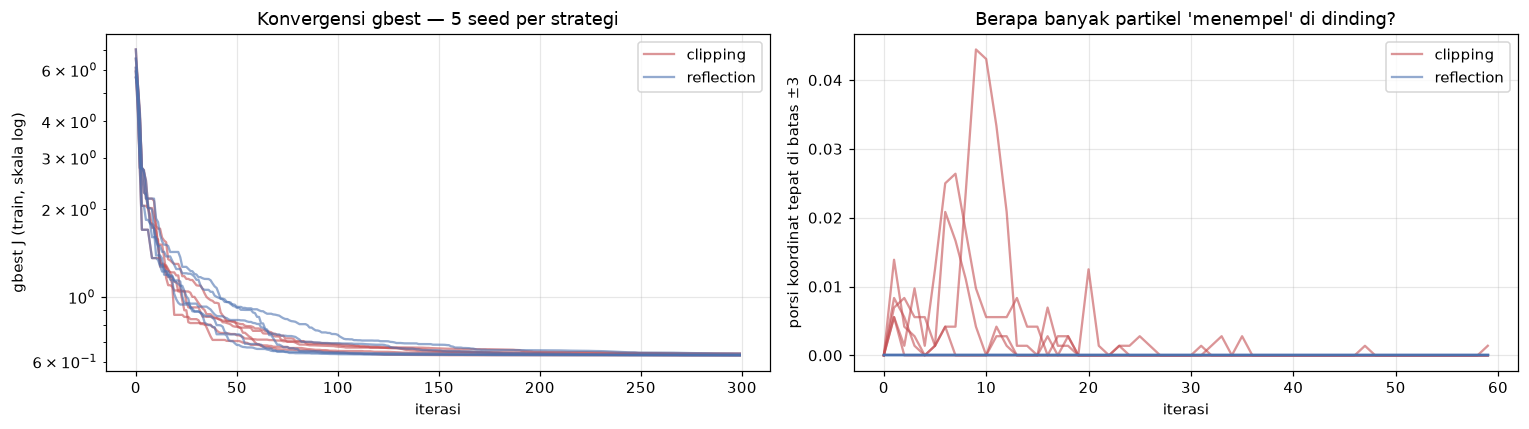

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for (label, s), h in curves.items():
    axes[0].plot(h, color="#C44E52" if label == "clipping" else "#4C72B0", alpha=.6,
                 label=label if s == SEED else None)
axes[0].set_yscale("log"); axes[0].set_xlabel("iterasi"); axes[0].set_ylabel("gbest J (train, skala log)")
axes[0].set_title("Konvergensi gbest — 5 seed per strategi"); axes[0].legend(); axes[0].grid(alpha=.3)
for (label, s), w in walls.items():
    axes[1].plot(w[:60], color="#C44E52" if label == "clipping" else "#4C72B0", alpha=.6,
                 label=label if s == SEED else None)
axes[1].set_xlabel("iterasi"); axes[1].set_ylabel("porsi koordinat tepat di batas ±3")
axes[1].set_title("Berapa banyak partikel 'menempel' di dinding?"); axes[1].legend(); axes[1].grid(alpha=.3)
plt.tight_layout(); plt.show()

**Hasil perbandingan boundary handling** (5 seed per strategi):

| | Clipping | Reflection |
|---|---|---|
| $J$ train akhir (mean ± std) | 0.6336 ± 0.0040 | 0.6327 ± 0.0036 |
| $J$ validation akhir | **0.6343** ± 0.0030 | 0.6348 ± 0.0035 |
| $J$ train di iterasi 20 | **1.111** | 1.203 |
| Porsi koordinat menempel di dinding (iterasi 10) | 1.2% (puncak 4.4%) | 0% |

- **Efek "menempel di dinding" memang terjadi pada clipping**, tetapi hanya di awal (iterasi 0–20, saat kecepatan masih besar), dan jumlahnya kecil (maks 4.4% koordinat). Reflection tidak pernah membuat partikel diam di dinding, persis seperti teorinya.
- Di kasus ini clipping malah **sedikit lebih cepat turun di awal** (J 1.11 vs 1.20 di iterasi 20). Masuk akal: partikel yang terlempar terlalu jauh langsung ditaruh di tepi ruang, sedangkan reflection memantulkannya kembali sejauh kelebihannya, kadang ke posisi yang lebih acak.
- **Hasil akhir praktis sama.** Selisih $J$ validation hanya 0.0005, jauh lebih kecil dari variasi antar-seed (std ±0.003). Alasannya, optimum (koefisien OLS sekitar ±0.8) berada **jauh di dalam** batas ±3, sehingga setelah partikel melambat, batas hampir tidak pernah tersentuh lagi.
- Sesuai aturan, strategi dipilih dari $J$ validation terkecil, yaitu **clipping**, walaupun bedanya tidak signifikan. Kalau optimum berada di dekat batas, atau batasnya sempit, perbedaan kedua strategi akan jauh lebih terasa.

## 5. Evaluation

### Jawaban 7c — Model akhir: RMSE, R², dan *convergence curve*

Strategi batas terpilih (J_val rata-rata terkecil): nearest


J train  PSO = 0.63209 | OLS = 0.63015 | rasio = 1.0031


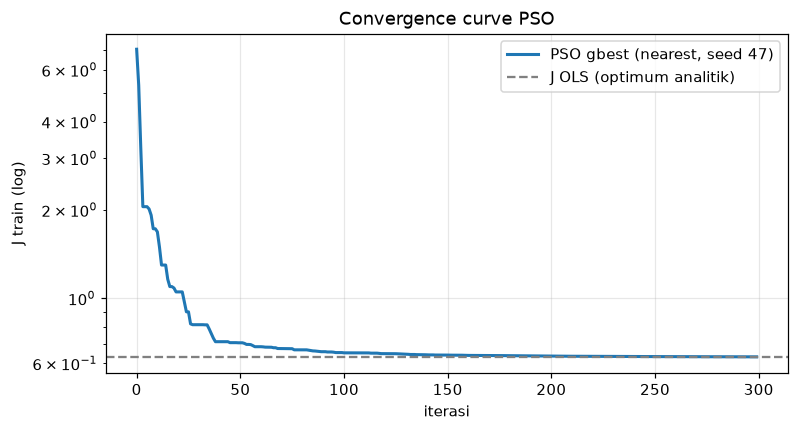

In [13]:
nama_bh = {"clipping": "nearest", "reflection": "reflective"}
BEST_BH = nama_bh[cmp_df.groupby("strategi")["J_val"].mean().idxmin()]   # dipilih dari validation
print("Strategi batas terpilih (J_val rata-rata terkecil):", BEST_BH)
theta, J_tr_best, hist_best, _ = run_pso(SEED, BEST_BH)

# Pembanding analitik: OLS (least squares) pada data latih yang sama
ols = LinearRegression().fit(Xs_tr, (Y_tr - y_mu) / y_sd)
theta_ols = np.concatenate([ols.coef_[0], [ols.intercept_[0]], ols.coef_[1], [ols.intercept_[1]]])
print(f"J train  PSO = {J_tr_best:.5f} | OLS = {J_single(theta_ols, Xs_tr, Y_tr):.5f} "
      f"| rasio = {J_tr_best / J_single(theta_ols, Xs_tr, Y_tr):.4f}")

plt.figure(figsize=(8, 4))
plt.plot(hist_best, lw=2, label=f"PSO gbest ({BEST_BH}, seed 47)")
plt.axhline(J_single(theta_ols, Xs_tr, Y_tr), ls="--", c="gray", label="J OLS (optimum analitik)")
plt.yscale("log"); plt.xlabel("iterasi"); plt.ylabel("J train (log)"); plt.title("Convergence curve PSO")
plt.legend(); plt.grid(alpha=.3); plt.show()

In [14]:
def report(theta_, Xs, Y, name):
    P = predict(theta_, Xs)
    out = []
    for k, t in enumerate(TARGET):
        out.append({"model": name, "target": t, "RMSE": np.sqrt(mean_squared_error(Y[:, k], P[:, k])),
                    "MAE": mean_absolute_error(Y[:, k], P[:, k]), "R2": r2_score(Y[:, k], P[:, k]),
                    "RMSE/σ_train": np.sqrt(mean_squared_error(Y[:, k], P[:, k])) / y_sd[k]})
    return out

res = pd.DataFrame(report(theta, Xs_tr, Y_tr, "PSO – train") + report(theta, Xs_va, Y_va, "PSO – val")
                   + report(theta, Xs_te, Y_te, "PSO – TEST") + report(theta_ols, Xs_te, Y_te, "OLS – TEST"))
print("J test PSO =", round(J_single(theta, Xs_te, Y_te), 4))
res.round(4)

J test PSO = 0.6132


,model,target,RMSE,MAE,R2,RMSE/σ_train
0,PSO – train,Heating_Load,2.9998,2.1257,0.9113,0.2978
1,PSO – train,Cooling_Load,3.1560,2.2662,0.8883,0.3342
2,PSO – val,Heating_Load,2.9218,2.0826,0.9098,0.2901
3,PSO – val,Cooling_Load,3.2749,2.3871,0.8748,0.3468
4,PSO – TEST,Heating_Load,2.6909,1.9606,0.9338,0.2672
5,PSO – TEST,Cooling_Load,3.2668,2.1787,0.8919,0.3460
6,OLS – TEST,Heating_Load,2.7019,1.9803,0.9332,0.2683
7,OLS – TEST,Cooling_Load,3.2817,2.2008,0.8909,0.3476


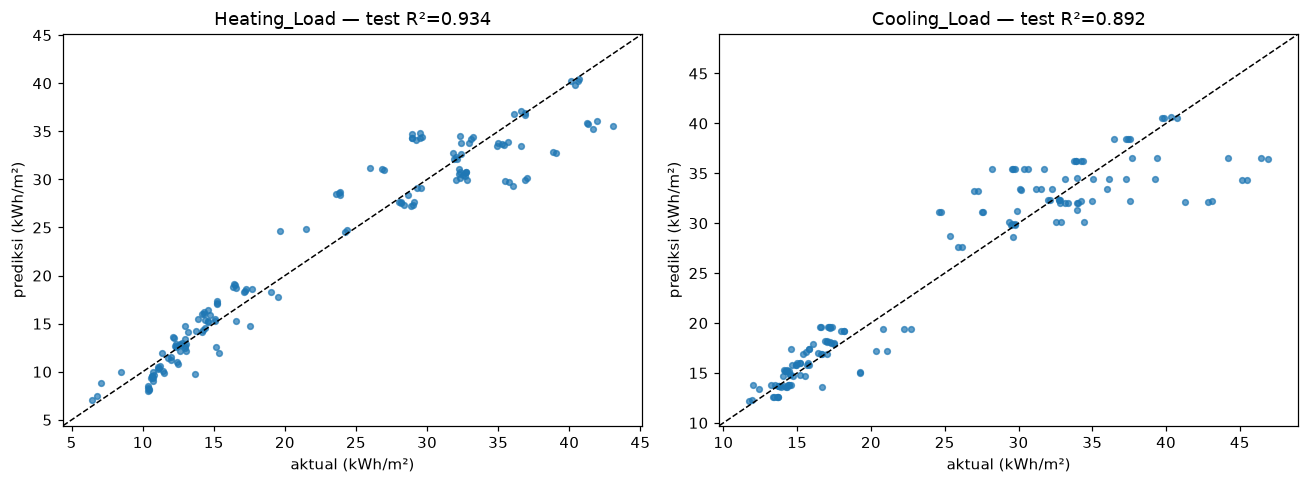

In [15]:
P_te = predict(theta, Xs_te)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for k, ax in enumerate(axes):
    ax.scatter(Y_te[:, k], P_te[:, k], s=14, alpha=.7)
    lim = [Y_te[:, k].min() - 2, Y_te[:, k].max() + 2]
    ax.plot(lim, lim, "k--", lw=1); ax.set_xlim(lim); ax.set_ylim(lim)
    ax.set_xlabel("aktual (kWh/m²)"); ax.set_ylabel("prediksi (kWh/m²)")
    ax.set_title(f"{TARGET[k]} — test R²={r2_score(Y_te[:, k], P_te[:, k]):.3f}")
plt.tight_layout(); plt.show()

**Hasil Jawaban 7c.**

| Target | RMSE test | MAE test | R² test | RMSE/σ |
|---|---|---|---|---|
| Heating Load ($Y_1$) | **2.69** kWh/m² | 1.96 | **0.934** | 0.267 |
| Cooling Load ($Y_2$) | **3.27** kWh/m² | 2.18 | **0.892** | 0.346 |

- **$J$ test = 0.613**, hampir sama dengan $J$ train (0.632) dan validation (0.634). Model linear dengan 18 parameter untuk 460 data latih **tidak overfit**.
- **PSO berhasil mendekati optimum analitik.** $J$ train PSO = 0.6321 vs OLS = 0.6302 (hanya 0.3% lebih buruk), dan di test set metrik PSO hampir identik dengan OLS (R² 0.934 vs 0.933). Kurva konvergensi turun tajam di 50 iterasi pertama lalu melandai mendekati garis OLS.
- **Heating lebih mudah diprediksi daripada Cooling.** Di plot prediksi-vs-aktual, Cooling Load lebih menyebar di nilai tinggi (>35 kWh/m²). Kemungkinan karena beban pendingin dipengaruhi interaksi kaca × orientasi × tinggi yang tidak bisa ditangkap model linear murni.
- Plot juga memperlihatkan pola "bergelombang" dan beberapa titik yang selalu meleset di kelompok gedung tinggi. Ini tanda **hubungan non-linear** (misalnya efek kekompakan tidak lurus). Model linear sudah bagus (R² ≈ 0.9), tetapi bukan batas akhir.

### Jawaban 7d — Fitur paling dominan dan keterbatasan interpretasinya

Karena fitur dan target sudah distandardisasi, koefisien bisa dibaca sebagai: *"kalau fitur ini naik 1 standar deviasi (fitur lain tetap), beban energi berubah sekian standar deviasi"*. Makin besar |koefisien|, makin dominan, **asalkan fitur-fiturnya tidak saling berkorelasi**.

,Heating (Y1),Cooling (Y2),|rata2|
Surface_Area,0.934,-1.894,1.414
Roof_Area,-1.853,0.747,1.300
Relative_Compactness,-0.746,-0.998,0.872
Overall_Height,0.692,0.625,0.658
Wall_Area,-0.632,0.657,0.645
Glazing_Area,0.264,0.200,0.232
Glazing_Area_Distribution,0.027,-0.000,0.014
Orientation,-0.009,-0.002,0.005


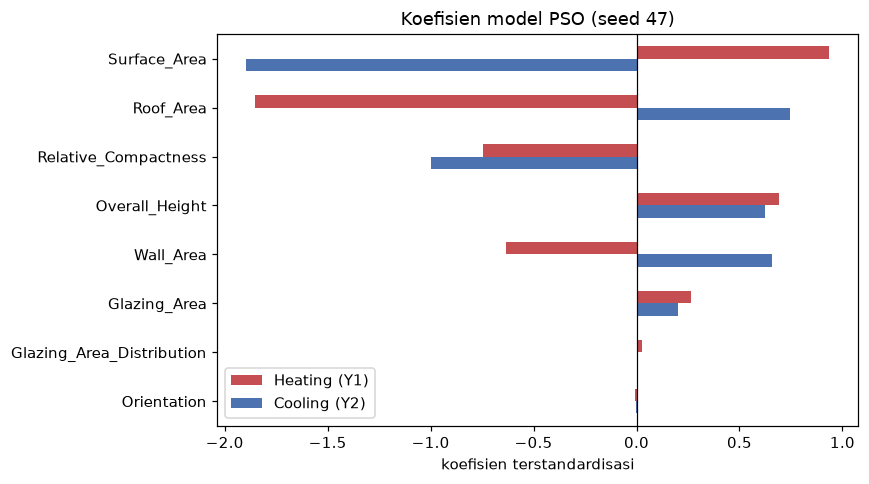

In [16]:
coef = pd.DataFrame({"Heating (Y1)": theta[0:8], "Cooling (Y2)": theta[9:17]}, index=FEAT)
coef["|rata2|"] = coef.abs().mean(axis=1)
coef = coef.sort_values("|rata2|", ascending=False)
display(coef.round(3))
coef[["Heating (Y1)", "Cooling (Y2)"]].plot.barh(figsize=(8, 4.5), color=["#C44E52", "#4C72B0"])
plt.gca().invert_yaxis(); plt.axvline(0, c="k", lw=.8); plt.xlabel("koefisien terstandardisasi")
plt.title("Koefisien model PSO (seed 47)"); plt.tight_layout(); plt.show()

**Uji kestabilan koefisien.** Kalau koefisien memang mencerminkan "pengaruh asli" sebuah fitur, nilainya seharusnya sama setiap kali PSO dijalankan ulang. Di bawah ini PSO dijalankan dengan 5 seed, lalu dilihat seberapa berbeda koefisiennya padahal nilai $J$-nya hampir sama.

In [17]:
seed_coefs, seed_J = [], []
for s in range(SEED, SEED + 5):
    th, c, _, _ = run_pso(s, BEST_BH)
    seed_coefs.append(th[0:8]); seed_J.append(c)
sc = pd.DataFrame(seed_coefs, columns=FEAT, index=[f"seed {s}" for s in range(SEED, SEED + 5)]).T
sc["std antar-seed"] = sc.std(axis=1)
print("J train per seed:", np.round(seed_J, 5))
sc.round(3)

J train per seed: [0.63209 0.63498 0.63024 0.64    0.63086]


,seed 47,seed 48,seed 49,seed 50,seed 51,std antar-seed
Relative_Compactness,-0.746,-0.421,-0.590,0.096,-0.462,0.318
Surface_Area,0.934,-0.445,0.097,0.221,-0.933,0.707
Wall_Area,-0.632,0.258,-0.120,0.181,0.475,0.428
Roof_Area,-1.853,0.070,-0.733,0.116,0.524,0.943
Overall_Height,0.692,0.847,0.784,1.059,0.836,0.135
Orientation,-0.009,-0.008,-0.007,-0.006,-0.006,0.001
Glazing_Area,0.264,0.265,0.269,0.275,0.268,0.004
Glazing_Area_Distribution,0.027,0.024,0.026,0.023,0.028,0.002


In [18]:
# Karena Surface = Wall + 2·Roof, kombinasi sd_S·zS − sd_W·zW − 2·sd_R·zR selalu bernilai 0.
# Menambahkan arah ini ke koefisien tidak mengubah prediksi sedikit pun.
arah = np.array([x_sd[1], -x_sd[2], -2 * x_sd[3]])
arah /= np.abs(arah).max()                 # perubahan koefisien terbesar = 1.0
theta_geser = theta.copy()
theta_geser[1:4] += arah
print("Koefisien Heating asli  :", np.round(theta[1:4], 3), " (Surface, Wall, Roof)")
print("Koefisien Heating geser :", np.round(theta_geser[1:4], 3))
print("J train asli  = %.6f" % J_single(theta, Xs_tr, Y_tr))
print("J train geser = %.6f" % J_single(theta_geser, Xs_tr, Y_tr))

Koefisien Heating asli  : [ 0.934 -0.632 -1.853]  (Surface, Wall, Roof)
Koefisien Heating geser : [ 1.894 -1.124 -2.853]
J train asli  = 0.632094
J train geser = 0.632094


**Hasil Jawaban 7d.**

**1. Fitur yang benar-benar dominan dan stabil.**
- **Overall_Height** (koefisien +0.69 Heating, +0.63 Cooling) konsisten positif di semua seed (0.69–1.06). Gedung 7 m punya volume dua kali lipat, sehingga beban energinya jauh lebih besar.
- **Glazing_Area** (+0.26 / +0.20) sangat stabil (std antar-seed 0.004): makin banyak kaca, makin banyak panas yang keluar-masuk.
- **Orientation** dan **Glazing_Area_Distribution** koefisiennya ≈ 0 di semua seed, jadi **tidak berpengaruh**. Ini cocok dengan korelasinya yang hampir nol.

**2. Koefisien yang tidak bisa dipercaya: Surface, Wall, Roof, Compactness.** Kalau dibaca mentah dari seed 47, fitur "paling dominan" adalah Surface_Area (|1.41|) dan Roof_Area (|1.30|). Tapi lihat tabel antar-seed:
- Koefisien Roof_Area untuk Heating bisa **−1.85 (seed 47)** atau **+0.52 (seed 51)**, bahkan berganti tanda.
- Surface_Area berkisar **−0.93 sampai +0.93**.
- Padahal $J$ kelima seed hampir sama (0.630–0.640).

**Penyebabnya:** karena Surface = Wall + 2·Roof secara persis, ada **tak terhingga kombinasi koefisien yang menghasilkan prediksi identik**. Sel terakhir membuktikannya: koefisien (Surface, Wall, Roof) digeser dari (0.93, −0.63, −1.85) ke (1.89, −1.12, −2.85), dan $J$ train tetap **0.632094**, sama persis sampai 6 desimal. Ibaratnya tiga orang mengangkat satu meja: berat total yang diangkat selalu sama, tetapi pembagian beban per orang bisa berapa saja, jadi kita tidak bisa bilang siapa yang "paling kuat". PSO hanya berhenti di salah satu kombinasi, tergantung titik awal acaknya.

**3. Kesimpulan interpretasi.**
- Magnitudo koefisien hanya sah dibandingkan bila fitur **tidak saling berkorelasi**. Di dataset ini, kesimpulan yang aman hanya: *tinggi gedung dan luas kaca menaikkan beban energi, sedangkan orientasi tidak berpengaruh*.
- Pengaruh "geometri" (compactness, surface, wall, roof) secara **bersama-sama** jelas penting, tetapi tidak bisa dipisah per fitur.
- Kalau interpretasi per fitur dibutuhkan, solusinya: (a) buang salah satu fitur yang kolinear sempurna (misalnya Surface_Area) dan gabungkan fitur yang berkorelasi tinggi, (b) tambahkan regularisasi L2 (ridge) di objective supaya PSO memilih solusi dengan koefisien sekecil mungkin yang unik, atau (c) gunakan *permutation importance per kelompok fitur*.
- Gejala ini juga menjelaskan kenapa seed 50 berhenti di $J$ = 0.640: *landscape* objective punya "lembah datar" di arah kolinear, sehingga PSO berkeliaran di sana tanpa dorongan untuk mendekati satu titik.

## 6. Interpretasi Hasil

### 6.1 Uji pada data baru: prediksi vs aktual (20 bangunan dari test set)

In [19]:
tab = pd.DataFrame(X_te[:20], columns=FEAT)[["Relative_Compactness", "Overall_Height", "Glazing_Area"]]
tab["Heating_aktual"], tab["Heating_prediksi"] = Y_te[:20, 0], P_te[:20, 0].round(2)
tab["Cooling_aktual"], tab["Cooling_prediksi"] = Y_te[:20, 1], P_te[:20, 1].round(2)
tab["error_Heating"] = (tab["Heating_prediksi"] - tab["Heating_aktual"]).round(2)
tab["error_Cooling"] = (tab["Cooling_prediksi"] - tab["Cooling_aktual"]).round(2)
tab

,Relative_Compactness,Overall_Height,Glazing_Area,Heating_aktual,Heating_prediksi,Cooling_aktual,Cooling_prediksi,error_Heating,error_Cooling
0,0.74,3.5,0.10,10.36,8.00,13.43,12.59,-2.36,-0.84
1,0.62,3.5,0.40,17.14,18.27,17.20,19.54,1.13,2.34
2,0.71,3.5,0.40,14.40,15.42,17.27,17.96,1.02,0.69
3,0.64,3.5,0.40,19.48,17.75,22.72,19.38,-1.73,-3.34
4,0.98,7.0,0.40,32.21,31.03,33.95,32.00,-1.18,-1.95
5,0.79,7.0,0.40,41.26,35.82,46.44,36.52,-5.44,-9.92
6,0.64,3.5,0.25,17.52,14.71,21.09,17.22,-2.81,-3.87
7,0.90,7.0,0.40,36.57,33.48,36.10,34.44,-3.09,-1.66
8,0.76,7.0,0.25,36.13,36.78,37.58,38.43,0.65,0.85
9,0.76,7.0,0.25,36.86,36.88,37.28,38.41,0.02,1.13


**Interpretasi uji akhir.** Pada 20 bangunan test, kebanyakan prediksi meleset hanya 0–3 kWh/m², kesalahan yang kecil dibanding rentang beban 6–43 kWh/m². Kesalahan terbesar ada di gedung tinggi dengan kaca 40% (baris 5: Cooling aktual 46.4, prediksi 36.5). Ini kasus ekstrem di mana efek tinggi dan kaca saling memperkuat (interaksi) dan tidak tertangkap model linear.

### 6.2 Pengecekan kriteria kesuksesan

| Kriteria | Target | Hasil | Status |
|---|---|---|---|
| $J_{PSO}$ ≤ 1.01 × $J_{OLS}$ (train) | ≤ 1.01 | 1.0031 (seed 47) | ✅ (4 dari 5 seed; seed 50 = 1.016) |
| R² test Heating | ≥ 0.85 | 0.934 | ✅ |
| R² test Cooling | ≥ 0.85 | 0.892 | ✅ |
| RMSE ≤ 0.4 σ | ≤ 0.4 | 0.267 / 0.346 | ✅ |

### 6.3 Kesimpulan
1. Satu partikel 18 dimensi berhasil mengoptimasi dua model linear sekaligus. Normalisasi RMSE dengan σ membuat kedua target diperlakukan adil.
2. PSO mencapai hasil yang praktis sama dengan solusi analitik OLS (R² test 0.934 Heating dan 0.892 Cooling) tanpa overfitting.
3. *Clipping* dan *reflection* menghasilkan model akhir yang sama karena optimum jauh dari batas. Perbedaannya hanya di awal pencarian: clipping sempat membuat beberapa partikel menempel di dinding.
4. Fitur dominan yang bisa dipercaya: **Overall_Height** dan **Glazing_Area**. Koefisien fitur geometri lain **tidak dapat diinterpretasi per fitur** karena Surface = Wall + 2·Roof (kolinear sempurna). Ini dibuktikan secara numerik: koefisien berbeda menghasilkan $J$ yang identik.
5. Pengembangan: tambahkan regularisasi atau buang fitur kolinear agar koefisien unik, dan tambahkan suku interaksi atau non-linear (misalnya tinggi × kaca) untuk menangkap sisa error pada Cooling Load.